In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import minimize
import scipy.stats as stats
import matplotlib.pyplot as plt
 

In [2]:
# Chargement des données
df = pd.read_excel('Test.xlsx', sheet_name=0)
df['Date'] = pd.to_datetime(df['Name'])
df = df.set_index('Date')
print(df.head())

# Sélection et renommage
prices = df[['BEL-DS', 'US-DS', 'USD-BIT']].copy()
prices.columns = ['Bel', 'US', 'BTC']
print(prices.head())

# Conversion en numérique et calcul des rendements logs
for col in prices.columns:
    prices[col] = pd.to_numeric(prices[col], errors='coerce')

returns = np.log(prices) - np.log(prices.shift(1))
print(returns.head())

In [3]:
#Modèle r1m
b0_1 = 0.000627152

#Modèle r2m
b0_2 = 0.000566268

#Matrice C 
c11 = 0.00000190387
c12 = 0.00000049943
c22 = 0.00000184726

#Matrice A
a11 = 0.04816
a22 = 0.03535
a33 = 0.07479

#Matrice B
b11 = 0.93629
b22 = 0.94541
b33 = 0.90548

In [4]:
#--- 4. Boucle sur l'ensemble des données ---
# Préparation des données
data_loop = returns[['Bel', 'US']].dropna()
T = len(data_loop)
r1 = data_loop['Bel'].values
r2 = data_loop['US'].values

# Initialisation des vecteurs pour stocker les résultats
r1m = np.zeros(T)
r2m = np.zeros(T)
eps1 = np.zeros(T)
eps2 = np.zeros(T)
eps1_2 = np.zeros(T)
eps2_2 = np.zeros(T)
eps_cross = np.zeros(T)

eps1[0] = r1[0]
eps2[0] = r2[0]
eps_cross[0] = eps1[0] * eps2[0]

for t in range(1, T):
    r1m[t] = b0_1 
    r2m[t] = b0_2
    eps1[t] = r1[t] - r1m[t]
    eps2[t] = r2[t] - r2m[t]
    eps1_2[t] = eps1[t] * eps1[t]
    eps2_2[t] = eps2[t] * eps2[t]
    eps_cross[t] = eps1[t] * eps2[t]

# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_eps = pd.DataFrame({'eps1': eps1, 'eps2': eps2}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '1990-01-03'
date_end = '2021-07-23'

subset = df_eps.loc[date_start:date_end]

# Création des variables demandées
eps1_col = subset['eps1'].values
eps2_col = subset['eps2'].values

# Initialisation des vecteurs de variance pour stocker les résultats
h11_t = np.zeros(T)
h12_t = np.zeros(T)
h22_t = np.zeros(T)

# Valeurs initiales (Variance inconditionnelle empirique)  t=1  
h11_t[0] = np.var(eps1_col)
h12_t[0] = np.cov(eps1_col, eps2_col)[0, 1]
h22_t[0] = np.var(eps2_col)


print(h11_t[0], h12_t[0], h22_t[0])

#Calcul valeur t=2
h11_t[1] = c11 + a11*eps1[0]**2 + b11*h11_t[0]
h12_t[1] = c12 + a22*eps_cross[0] + b22*h12_t[0]
h22_t[1] = c22 + a33*eps2[0]**2 + b33*h22_t[0]


#Calcul valeur t=3 to T
for t in range(2, T): 
    h11_t[t] = c11 + a11*eps1[t-1]**2 + b11*h11_t[t-1]
    h12_t[t] = c12 + a22*eps_cross[t-1] + b22*h12_t[t-1]
    h22_t[t] = c22 + a33*eps2[t-1]**2 + b33*h22_t[t-1]



0.0001276588961963293 5.448577602128915e-05 0.00012267946351565364


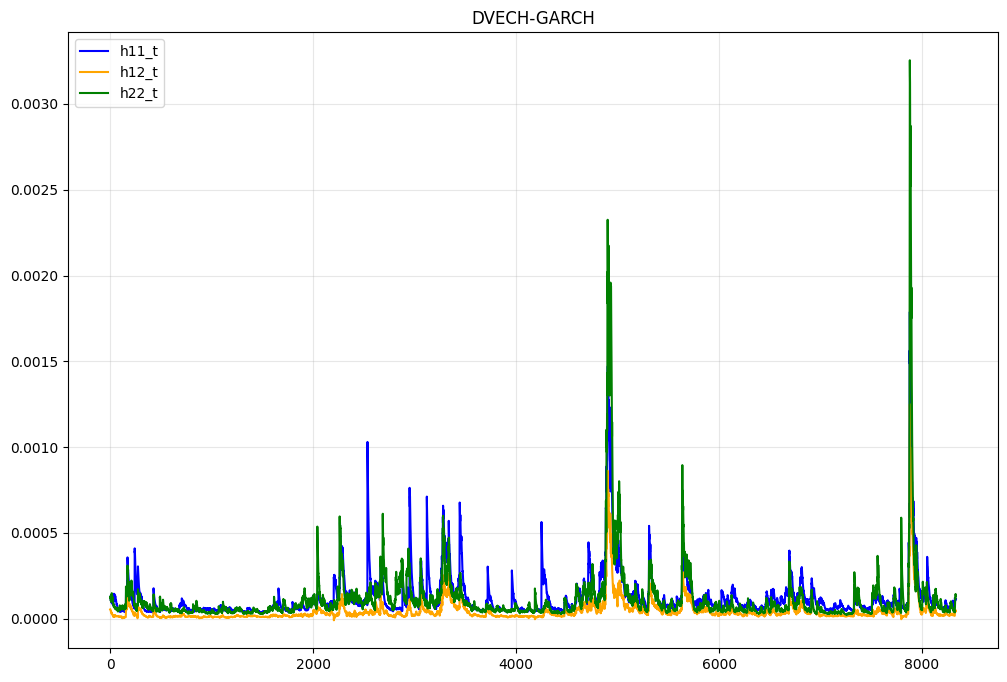

In [5]:
plt.figure(figsize=(12,8))
plt.plot(h11_t, 'b-', label='h11_t', lw=1.5)
plt.plot(h12_t, 'orange', label='h12_t', lw=1.5)
plt.plot(h22_t, 'g-', label='h22_t', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('DVECH-GARCH'); plt.show()


In [6]:
# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_Dvech = pd.DataFrame({'r1': r1, 'r1m': r1m, 'h11_t': h11_t}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '2021-07-23'
date_end = '2021-12-09'

subset = df_Dvech.loc[date_start:date_end]

# Création des variables demandées
n_subset = len(subset)
r1_new = subset['r1'].values
r1m_new = subset['r1m'].values
h11_t_new = subset['h11_t'].values

VaR = np.zeros(n_subset)
Val_V = np.zeros(n_subset)
Perte = np.zeros(n_subset)


Val_V[0] = 100000 * (1 + r1_new[0])
Val_V[1] = Val_V[0] * (1 + r1_new[1])
Perte[0] = 100000 - Val_V[0]
Perte[1] = Val_V[0] - Val_V[1]

for t in range(2, n_subset):
    Val_V[t] = Val_V[t-1] * (1 + r1_new[t])
    Perte[t] = Val_V[t-1] - Val_V[t]


VaR[0] = 100000 * ((-r1m_new[0] + 1.645 * (h11_t_new[0]**0.5)))
for t in range(1, n_subset):
    VaR[t] = Val_V[t-1]*((-r1m_new[t]+ 1.645*(h11_t_new[t]**0.5)))

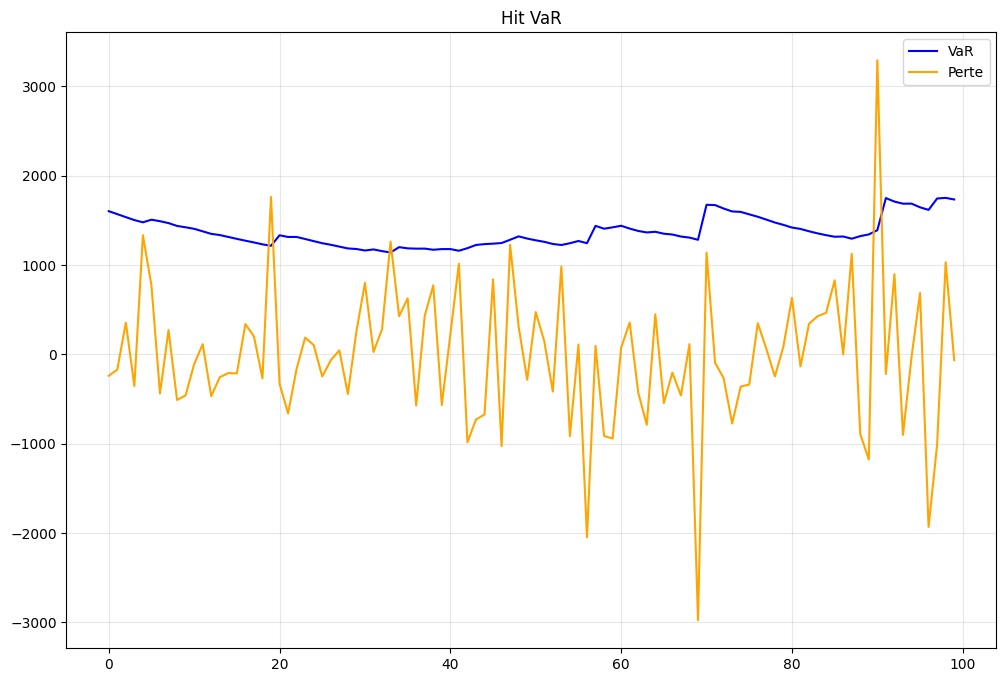

In [7]:
plt.figure(figsize=(12,8))
plt.plot(VaR, 'b-', label='VaR', lw=1.5)
plt.plot(Perte, 'orange', label='Perte', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('Hit VaR'); plt.show()

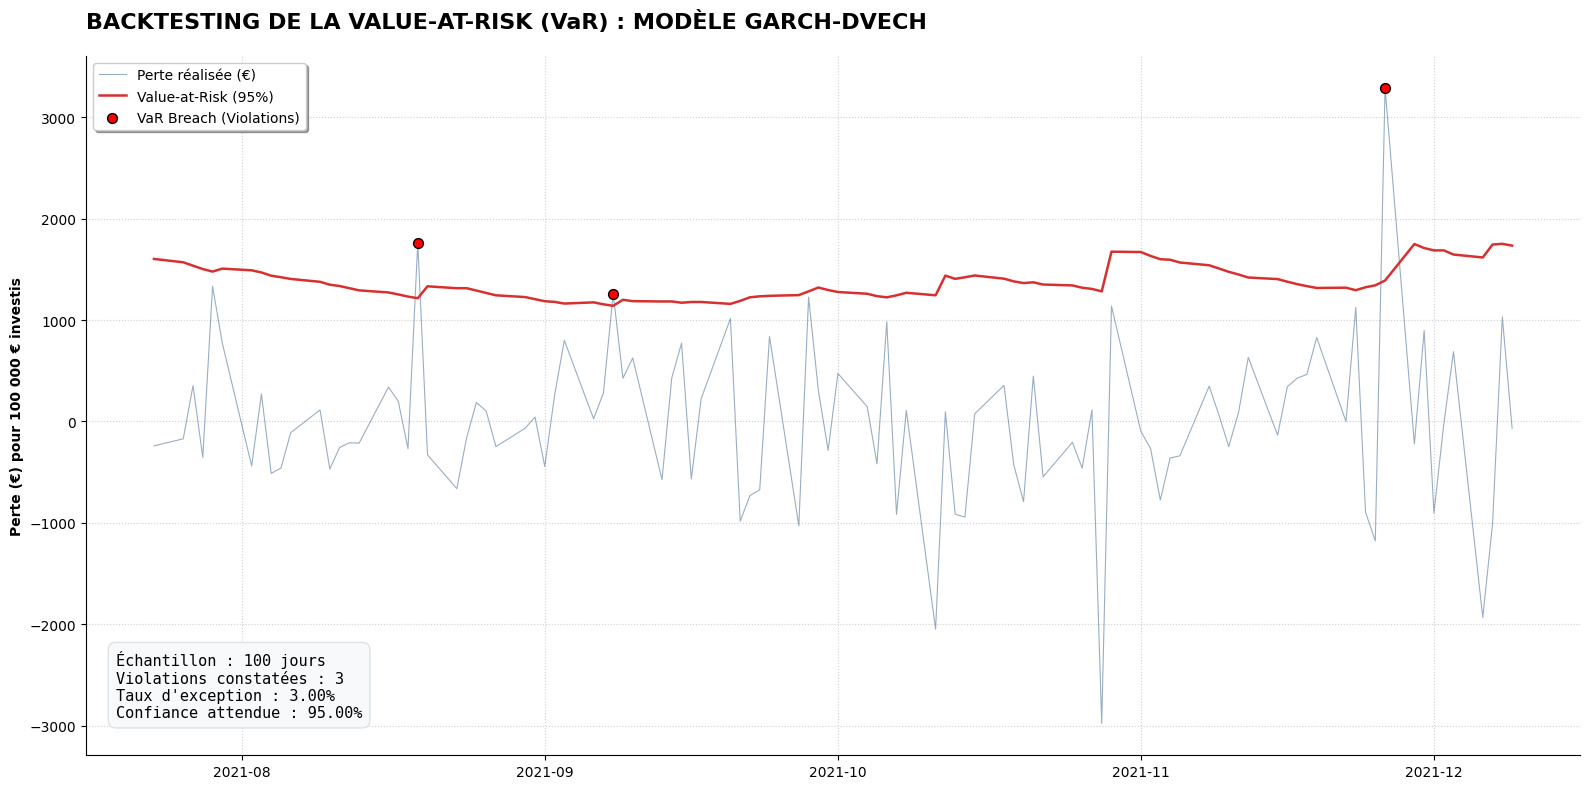

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# --- 1. SYNCHRONISATION DES DIMENSIONS ---
# L'index temporel est ajusté à la taille de vos prévisions (les 100 dernières observations)
plot_index = data_loop.index[-len(Perte):]

# --- 2. CONFIGURATION DU STYLE "RISK AUDIT" ---
plt.style.use('default')
fig, ax = plt.subplots(figsize=(16, 8), facecolor='white')
ax.set_facecolor('white')

# 3. IDENTIFICATION DES VIOLATIONS (perte > VaR)
# Une violation se produit quand la perte réalisée dépasse la VaR
hits = Perte > VaR 

# 4. TRACÉ DES SÉRIES PRINCIPALES
# Rendements en bleu léger pour ne pas masquer le signal d'alerte
ax.plot(plot_index, Perte, color='#003366', lw=0.8, alpha=0.4, label='Perte réalisée (€)')

# VaR en rouge vif (Seuil de risque)
ax.plot(plot_index, VaR, color='#d63031', lw=1.8, label=f'Value-at-Risk (95%)', zorder=4)

# 5. MARQUAGE DES VIOLATIONS (SIGNAL TERMINAL)
# On affiche des points rouges (les "hits") uniquement aux dates de dépassement
ax.scatter(plot_index[hits], Perte[hits], color='#ff0000', s=50, 
           label='VaR Breach (Violations)', zorder=5, edgecolor='black', marker='o')

# 6. HABILLAGE "FRONT OFFICE"
ax.set_title('BACKTESTING DE LA VALUE-AT-RISK (VaR) : MODÈLE GARCH-DVECH', 
             loc='left', fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel('Perte (€) pour 100 000 € investis', fontweight='bold')

# Ajout d'un cartouche de statistiques de performance (L'audit du Risk Manager)
nb_hits = np.sum(hits)
tx_exception = (nb_hits / len(Perte)) * 100
stats_audit = (f"Échantillon : {len(Perte)} jours\n"
               f"Violations constatées : {nb_hits}\n"
               f"Taux d'exception : {tx_exception:.2f}%\n"
               f"Confiance attendue : 95.00%")

ax.text(0.02, 0.05, stats_audit, transform=ax.transAxes, fontsize=11, family='monospace',
        verticalalignment='bottom', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#dee2e6'))

# Formatage des axes (Dates et Grille)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=0)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', frameon=True, shadow=True, fontsize=10)

# Nettoyage visuel
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [9]:
# Test de Kupiec (proportion de violations, POF) : le taux observé est-il compatible avec 5 % ?
from scipy.stats import chi2, binom

def kupiec_pof(nb_violations, n, p=0.05):
    """Statistique du rapport de vraisemblance de Kupiec et sa p-value (loi du khi-deux à 1 degré de liberté)."""
    x, pi = nb_violations, nb_violations / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - pi) + (x * np.log(pi) if x > 0 else 0.0)
    lr = -2 * (ll0 - ll1)
    return lr, 1 - chi2.cdf(lr, 1)

n_obs, x_obs = len(Perte), int(np.sum(Perte > VaR))
lr, pval = kupiec_pof(x_obs, n_obs, p=0.05)
bas, haut = int(binom.ppf(0.025, n_obs, 0.05)), int(binom.ppf(0.975, n_obs, 0.05))
print(f"Violations : {x_obs} sur {n_obs} jours (attendu : {0.05 * n_obs:.0f})")
print(f"Kupiec LR = {lr:.3f}, p-value = {pval:.3f} -> " + ("modèle non rejeté à 5 %" if pval > 0.05 else "modèle rejeté à 5 %"))
print(f"Zone d'acceptation à 95 % : de {bas} à {haut} violations")


Violations : 3 sur 100 jours (attendu : 5)
Kupiec LR = 0.977, p-value = 0.323 -> modèle non rejeté à 5 %
Zone d'acceptation à 95 % : de 1 à 10 violations
